# Capstone Milestone One — Week 6: Decision Trees and Random Forests

**Kumar Gaurav · DX799 O1 Data Science Capstone**

## Project Overview

Consumer credit risk is a central concern for lenders because mispriced loans and misjudged credit limits translate directly into losses and lost customers.

This analysis asks whether tree-based models — which learn if/then thresholds and interactions automatically — can predict default better than the linear and margin-based baselines on the same two consumer credit datasets. The random forest is the strongest nonlinear candidate and the depth model of this analysis, so it gets the most thorough tuning and diagnostics.

### Research Question

Can decision trees and random forests predict consumer default more accurately than logistic regression or SVMs on the same features, and does their advantage depend on whether the data have real threshold or interaction structure?

The two target variables used here are both binary:

* **Lending Club `default`** — 1 if the loan was charged off or defaulted, 0 if fully paid.
* **Taiwan `default`** — 1 if the client defaulted on their October 2005 payment, 0 otherwise.

### Objectives

The objectives of this analysis are to:

* Trace the decision-tree bias–variance curve by sweeping `max_depth` and the cost-complexity pruning parameter `ccp_alpha`.
* Fit a small readable depth-3 tree on each dataset for business interpretability.
* Tune a random forest with `RandomizedSearchCV` and inspect `min_samples_leaf` and `max_depth` validation curves plus the out-of-bag score.
* Compare impurity and permutation-based feature importance on the tuned forest.
* Choose a decision threshold on out-of-fold training predictions and apply it to the held-out test set.
* Produce a final head-to-head table against logistic regression, pruned decision tree, and tuned SVM on the same splits.

### Approach

The analysis follows a single modeling arc on both datasets:

Data Loading → Shared Classification Setup → Decision-Tree Diagnostics → Random-Forest Tuning and Diagnostics → Final Cross-Model Comparison → Summary

### Datasets

* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans, 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005, with a target of default in October 2005.

## 1. Data Loading and Cleaning

The code cells below load the two raw files, apply the documented cleaning rules (outcome definition, invalid-range handling, undocumented-code recoding, log transforms, and target-leakage removal), and produce the cleaned `lc` and `tw` frames that the modeling sections use. The data-quality audit for these datasets is documented separately.

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42

# Lending Club: read only the columns we audit/model (the raw file is 2.26M x 145)
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv/versions/1"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           # post-outcome columns, loaded ONLY to demonstrate the leakage screen
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)
print(f"Lending Club raw shape (audited columns): {lc_raw.shape}")
print(lc_raw.dtypes.value_counts().to_string())
display(lc_raw.head(3))

Lending Club raw shape (audited columns): (2260668, 28)
float64    16
str         9
int64       3


,id,loan_amnt,term,int_rate,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,revol_util,total_acc,out_prncp,total_pymnt,recoveries,last_pymnt_amnt,policy_code,application_type,mort_acc,pub_rec_bankruptcies
0,NaN,2500,36 months,13.56,C,C1,10+ years,RENT,55000.0,Not Verified,...,10.3,34.0,2386.02,167.02,0.0,84.92,1,Individual,0.0,1.0
1,NaN,30000,60 months,18.94,D,D2,10+ years,MORTGAGE,90000.0,Source Verified,...,24.2,44.0,29387.75,1507.11,0.0,777.23,1,Individual,3.0,1.0
2,NaN,5000,36 months,17.97,D,D1,6 years,MORTGAGE,59280.0,Source Verified,...,19.1,13.0,4787.21,353.89,0.0,180.69,1,Individual,2.0,0.0


In [2]:
# Keep closed loans only (outcome known); 'Current'/'Late' loans are censored
CLOSED = ["Fully Paid", "Charged Off", "Default"]
print("loan_status counts:"); print(lc_raw["loan_status"].value_counts().to_string())
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].copy()
print(f"\nClosed loans: {len(lc):,}")

dq = []  # (issue, rows affected, action)
dq.append(("Open/censored loan_status", len(lc_raw) - len(lc), "dropped (outcome unknown)"))
dq.append(("id column 100% null", 0, "cannot dedupe on id; deduped on full row instead"))
dups = lc.drop(columns=["id"]).duplicated().sum(); dq.append(("Exact duplicate rows", dups, "dropped"))
lc = lc.drop(columns=["id"]).drop_duplicates()

# Invalid / impossible ranges
bad_dti = ((lc["dti"] < 0) | (lc["dti"] > 100)).sum()
dq.append(("dti < 0 or > 100% (sentinel 999 / data error)", bad_dti, "set to NaN then dropped"))
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
hi_util = (lc["revol_util"] > 100).sum()
dq.append(("revol_util > 100%", hi_util, "clipped to 150 (over-limit is real but extreme)"))
lc["revol_util"] = lc["revol_util"].clip(upper=150)
zero_inc = (lc["annual_inc"] <= 0).sum()
dq.append(("annual_inc <= 0", zero_inc, "dropped (cannot log/ratio)"))
lc = lc[lc["annual_inc"] > 0]
hi_inc = (lc["annual_inc"] > 1e6).sum()
dq.append(("annual_inc > $1M", hi_inc, "kept; modeled as log1p(annual_inc)"))
odd_home = lc["home_ownership"].isin(["ANY", "NONE", "OTHER"]).sum()
dq.append(("home_ownership ANY/NONE/OTHER", odd_home, "merged into OTHER"))
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})

# Constant / near-constant and cardinality
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
print("Constant columns:", const)
dq.append(("Constant columns " + str(const), 0, "column dropped (no information)"))
lc = lc.drop(columns=const)
cat_cols = lc.select_dtypes("object").columns
print("Categorical cardinality:", lc[cat_cols].nunique().to_dict())

# Leakage screen: columns only known AFTER the outcome
LEAK = ["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
print("\nLeakage check: mean of post-outcome columns by outcome")
print(lc.groupby(lc["loan_status"] != "Fully Paid")[LEAK].mean().round(1).rename(index={False: "repaid", True: "default"}).to_string())
dq.append(("Post-outcome columns " + ", ".join(LEAK), 0, "columns dropped (target leakage)"))
lc = lc.drop(columns=LEAK)

lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
before = len(lc)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies", "inq_last_6mths", "open_acc", "total_acc"])
dq.append(("Remaining NaNs in model columns", before - len(lc), "dropped (listwise)"))
lc["log_annual_inc"] = np.log1p(lc["annual_inc"]); lc["log_revol_bal"] = np.log1p(lc["revol_bal"])
lc["term_months"] = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"\nClean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

loan_status counts:
loan_status
Fully Paid                                             1041952
Current                                                 919695
Charged Off                                             261655
Late (31-120 days)                                       21897
In Grace Period                                           8952
Late (16-30 days)                                         3737
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     31

Closed loans: 1,303,638
Constant columns: ['policy_code']
Categorical cardinality: {'term': 2, 'grade': 7, 'sub_grade': 35, 'emp_length': 11, 'home_ownership': 4, 'verification_status': 3, 'loan_status': 3, 'purpose': 14, 'application_type': 2}

Leakage check: mean of post-outcome columns by outcome
             total_pymnt  recoveries  last_pymnt_amnt  out_prncp
loan_status                       

In [3]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset/versions/1"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)
print(f"Taiwan raw shape: {tw_raw.shape}")
print(tw_raw.dtypes.value_counts().to_string())
display(tw_raw.head(3))

Taiwan raw shape: (30000, 25)
float64    13
int64      12


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0


In [4]:
tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY = [f"PAY_{i}" for i in range(1, 7)]; BILL = [f"BILL_AMT{i}" for i in range(1, 7)]; PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tdq = []
print("Null cells total:", int(tw.isnull().sum().sum()))
tdq.append(("Missing values", int(tw.isnull().sum().sum()), "none to handle"))
tdq.append(("Duplicate ID", int(tw["ID"].duplicated().sum()), "none"))
dup = int(tw.drop(columns="ID").duplicated().sum())
tdq.append(("Duplicate rows (ignoring ID)", dup, "dropped (identical profiles)"))
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()

print("EDUCATION codes:", tw["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE codes:", tw["MARRIAGE"].value_counts().sort_index().to_dict())
print("PAY_1 codes:", tw["PAY_1"].value_counts().sort_index().to_dict())
edu_bad = int(tw["EDUCATION"].isin([0, 5, 6]).sum())
tdq.append(("EDUCATION undocumented codes 0/5/6", edu_bad, "recoded to 4 = other"))
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
mar_bad = int((tw["MARRIAGE"] == 0).sum())
tdq.append(("MARRIAGE undocumented code 0", mar_bad, "recoded to 3 = other"))
tw["MARRIAGE"] = tw["MARRIAGE"].replace({0: 3})
pay_m2 = int((tw[PAY] == -2).any(axis=1).sum())
tdq.append(("PAY_* = -2 (no consumption, undocumented)", pay_m2, "kept as ordinal (-2 < -1 paid duly < 0 revolving)"))
neg_bill = int((tw[BILL] < 0).any(axis=1).sum())
tdq.append(("Negative BILL_AMT (credit balance/overpay)", neg_bill, "kept; signed log transform"))
tdq.append(("AGE range " + f"{tw['AGE'].min()}-{tw['AGE'].max()}", 0, "plausible, kept"))
const = [c for c in tw.columns if tw[c].nunique() <= 1]; tdq.append(("Constant columns", len(const), "none"))

# Leakage screen: all features are observed BEFORE the default month (Apr-Sep 2005 -> Oct 2005)
tdq.append(("Post-outcome columns", 0, "none: all features precede target month"))
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
for c in BILL + PAMT: tw["log_" + c] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"\nClean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Null cells total: 0
EDUCATION codes: {0: 14, 1: 10563, 2: 14019, 3: 4915, 4: 123, 5: 280, 6: 51}
MARRIAGE codes: {0: 54, 1: 13643, 2: 15945, 3: 323}
PAY_1 codes: {-2: 2750, -1: 5682, 0: 14737, 1: 3667, 2: 2666, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

Clean Taiwan rows: 29,965 | default rate: 22.13%


## Part B — Trees and Forests

### Key Concepts

* **Decision tree.** Repeatedly splits the data on the single feature/threshold that most reduces impurity (Gini = 1 − Σpₖ²; 0 for a pure node). The prediction at a leaf is the share of defaults in that leaf. Trees need no scaling and capture thresholds and interactions natively, but a deep tree memorizes the training data (high variance).
* **Controlling tree overfitting.** Limit `max_depth`, require `min_samples_leaf`, or grow the full tree and prune it with cost-complexity pruning (`ccp_alpha`: a split is kept only if it reduces impurity by more than α per extra leaf).
* **Random forest.** Averages hundreds of deep trees, each grown on a bootstrap sample (rows drawn with replacement) and allowed to consider only a random subset of features (`max_features`) at each split. Averaging many decorrelated noisy trees cancels much of their variance (bagging + feature randomness).
* **Out-of-bag (OOB) score.** Each tree never sees about 37% of the rows (those left out of its bootstrap sample); predicting those rows gives a built-in validation estimate without a separate holdout.

### 2. Shared Classification Setup

The Lending Club and Taiwan modeling uses the same split logic, the same preprocessing structure, and the same cross-validation protocol, so metrics are directly comparable between train and test.

* **Lending Club:** a 60,000-loan random sample of the cleaned closed loans (seed 42), split 80/20 **stratified** on `default` so both parts keep the roughly 20% default rate.
  * Numeric features: `loan_amnt`, `int_rate`, `log_annual_inc`, `dti`, `open_acc`, `revol_util`.
  * Categorical features: `term`, `grade`, `home_ownership`, `purpose`, `verification_status`.
* **Taiwan:** all 29,965 clean clients, split 80/20 stratified (seed 42).
  * Numeric features: `log_LIMIT_BAL`, `AGE`, `PAY_1..6`, `log_BILL_AMT1..6`, `log_PAY_AMT1..6`.
  * Categorical features: `SEX`, `EDUCATION`, `MARRIAGE`.

The `make_prep(num, cat, scale=True)` helper builds a `ColumnTransformer` that standardizes the numerics and one-hot encodes the categoricals. It is always fit inside a pipeline on training folds only, so no test-set leakage occurs. Trees do not need scaling but the same preprocessor is used so that the pipelines are structurally identical across all models.

Stratification matters here because with 20–22% positives, a random split could by chance put noticeably more defaults in one part. Stratifying guarantees equal rates.

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
FIG = "../../../week_10092026_w7/DX799O1/figures"; os.makedirs(FIG, exist_ok=True)

LC_NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "open_acc", "revol_util"]
LC_CAT = ["term", "grade", "home_ownership", "purpose", "verification_status"]
TW_NUM = ["log_LIMIT_BAL", "AGE"] + [f"PAY_{i}" for i in range(1, 7)] + [f"log_BILL_AMT{i}" for i in range(1, 7)] + [f"log_PAY_AMT{i}" for i in range(1, 7)]
TW_CAT = ["SEX", "EDUCATION", "MARRIAGE"]

lc_s = lc.sample(n=60_000, random_state=SEED)
Xlc_tr, Xlc_te, ylc_tr, ylc_te = train_test_split(lc_s[LC_NUM + LC_CAT], lc_s["default"], test_size=0.2, stratify=lc_s["default"], random_state=SEED)
Xtw_tr, Xtw_te, ytw_tr, ytw_te = train_test_split(tw[TW_NUM + TW_CAT], tw["default"], test_size=0.2, stratify=tw["default"], random_state=SEED)
DATA = {"Lending Club": (Xlc_tr, Xlc_te, ylc_tr, ylc_te, LC_NUM, LC_CAT),
        "Taiwan": (Xtw_tr, Xtw_te, ytw_tr, ytw_te, TW_NUM, TW_CAT)}
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_prep(num, cat, scale=True):
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", num),
                              ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat)])

def scores(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, prob),
            "pr_auc": average_precision_score(y, prob), "threshold": thr}

for name, (a, b, ya, yb, num, cat) in DATA.items():
    print(f"{name:12s} train {a.shape} default {ya.mean():.2%} | test {b.shape} default {yb.mean():.2%} | numeric {len(num)}, categorical {len(cat)}")

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
import time

Lending Club train (48000, 11) default 20.29% | test (12000, 11) default 20.29% | numeric 6, categorical 5
Taiwan       train (23972, 23) default 22.13% | test (5993, 23) default 22.13% | numeric 20, categorical 3


### Shared-Setup Findings

* **Lending Club:** train 48,000 × 11 and test 12,000 × 11. Both at 20.29% default, with 6 numeric and 5 categorical features.
* **Taiwan:** train 23,972 × 23 and test 5,993 × 23. Both at 22.13% default, with 20 numeric and 3 categorical features.

Stratification worked — the default rates are identical across splits. Two baselines to keep in mind:

* **Accuracy baseline.** An "everyone repays" rule scores 79.7% on Lending Club and 77.9% on Taiwan.
* **PR-AUC baseline.** A random ranking scores 0.203 on Lending Club and 0.221 on Taiwan.

### 3. Decision Tree — `max_depth` Sweep (Train vs 5-Fold CV AUC)

`max_depth` is the most direct complexity control. Plotting training and validation AUC against depth exposes the bias–variance trade-off: shallow trees underfit (both scores low); deep trees overfit (training AUC → 1, validation falls).

For depth 1–20 and unlimited, a 5-fold stratified CV computes mean train and validation AUC. `class_weight="balanced"` is used so the comparison against the balanced logistic model is apples to apples. Trees do not need scaling, but the same preprocessor is used so pipelines stay identical.

In [6]:
from sklearn.model_selection import cross_validate
depths = list(range(1, 21)) + [None]
dt_curves = {}
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    res = []
    for d_ in depths:
        pipe = Pipeline([("prep", make_prep(num, cat)), ("clf", DecisionTreeClassifier(max_depth=d_, class_weight="balanced", random_state=SEED))])
        cv = cross_validate(pipe, Xa, ya, cv=CV5, scoring="roc_auc", return_train_score=True, n_jobs=-1)
        res.append((d_ if d_ else 40, cv["train_score"].mean(), cv["test_score"].mean(), cv["test_score"].std()))
    dt_curves[name] = pd.DataFrame(res, columns=["max_depth", "train_auc", "cv_auc", "cv_sd"])
    b = dt_curves[name].loc[dt_curves[name].cv_auc.idxmax()]
    full = dt_curves[name].iloc[-1]
    print(f"{name}: best depth={int(b.max_depth)} CV AUC={b.cv_auc:.4f} +- {b.cv_sd:.4f} (train {b.train_auc:.4f}) | "
          f"unlimited depth: train {full.train_auc:.4f} vs CV {full.cv_auc:.4f}")
    display(dt_curves[name].iloc[[0, 2, 4, 6, 8, 11, 14, 19, 20]].round(4).T)

Lending Club: best depth=5 CV AUC=0.6898 +- 0.0044 (train 0.7005) | unlimited depth: train 1.0000 vs CV 0.5413


,0,2,4,6,8,11,14,19,20
max_depth,1.0000,3.0000,5.0000,7.0000,9.0000,12.0000,15.0000,20.0000,40.0000
train_auc,0.6325,0.6852,0.7005,0.7197,0.7523,0.8245,0.9022,0.9787,1.0000
cv_auc,0.6321,0.6827,0.6898,0.6835,0.6645,0.6266,0.5930,0.5593,0.5413
cv_sd,0.0045,0.0032,0.0044,0.0058,0.0025,0.0058,0.0053,0.0108,0.0071


Taiwan: best depth=6 CV AUC=0.7594 +- 0.0070 (train 0.7891) | unlimited depth: train 1.0000 vs CV 0.6057


,0,2,4,6,8,11,14,19,20
max_depth,1.0000,3.0000,5.0000,7.0000,9.0000,12.0000,15.0000,20.0000,40.0000
train_auc,0.6876,0.7520,0.7760,0.8024,0.8366,0.8982,0.9513,0.9902,1.0000
cv_auc,0.6876,0.7500,0.7586,0.7553,0.7374,0.7006,0.6545,0.6267,0.6057
cv_sd,0.0090,0.0041,0.0041,0.0056,0.0085,0.0138,0.0156,0.0086,0.0063


### Decision Tree Depth Findings

**Lending Club.**

* Best depth 5: CV AUC 0.6898 ± 0.0044 (train 0.7005).
* Beyond depth 5, CV AUC falls: 0.6645 at depth 9, 0.5930 at depth 15, and 0.5413 unlimited, while train AUC climbs to 1.0000.

**Taiwan.**

* Best depth 6: CV AUC 0.7594 ± 0.0070 (train 0.7891).
* An unlimited tree reaches train 1.0000 but CV 0.6057.

Three readings:

* **The bias–variance trade-off, in numbers.** Depth 1 (a single split) underfits (train and CV both ~0.63 / 0.69). Depths 5–6 are the sweet spot. An unlimited tree memorizes — on Lending Club its CV AUC of 0.54 is barely above a coin flip, even though it is perfect on the training data.
* **Fold SDs are small (0.003–0.016),** so the peak is reliable.
* **Already competitive on Taiwan.** A single depth-6 tree (0.759) beats a tuned linear model (CV around 0.752), because it captures the PAY threshold effects directly. On Lending Club the tree stays behind the linear baseline.

### 4. Cost-Complexity Pruning (`ccp_alpha`) and the Pruned Tree

Pruning is the second way to control tree size. `cost_complexity_pruning_path` lists every α at which a subtree collapses (thousands of values). 16 log-spaced α values from 10⁻⁵ (almost no pruning) to 10⁻² (a stump) are cross-validated, and the best is chosen.

This step tests whether a grow-then-prune tree (`min_samples_leaf = 5`) beats a depth-limited one. What to look for: the best α, the resulting number of leaves and depth, and the CV AUC compared with the best `max_depth` tree.

Lending Club: full pruning path has 2794 alphas (max 3.67e-02); searching 16 log-spaced values 1e-5..1e-2
   CV AUC by ccp_alpha: 1e-05:0.5778, 2e-05:0.5781, 3e-05:0.5792, 4e-05:0.5749, 6e-05:0.5845, 1e-04:0.6232, 2e-04:0.6809, 3e-04:0.6907, 4e-04:0.6895, 6e-04:0.6870, 1e-03:0.6811, 2e-03:0.6766, 3e-03:0.6695, 4e-03:0.6695, 6e-03:0.6428, 1e-02:0.6321
   best ccp_alpha=2.51e-04 CV AUC=0.6907 | leaves=24 depth=7
Taiwan: full pruning path has 1372 alphas (max 7.93e-02); searching 16 log-spaced values 1e-5..1e-2
   CV AUC by ccp_alpha: 1e-05:0.6692, 2e-05:0.6701, 3e-05:0.6709, 4e-05:0.6733, 6e-05:0.6697, 1e-04:0.6782, 2e-04:0.6972, 3e-04:0.7376, 4e-04:0.7616, 6e-04:0.7675, 1e-03:0.7633, 2e-03:0.7579, 3e-03:0.7475, 4e-03:0.7390, 6e-03:0.7354, 1e-02:0.6900
   best ccp_alpha=6.31e-04 CV AUC=0.7675 | leaves=19 depth=8


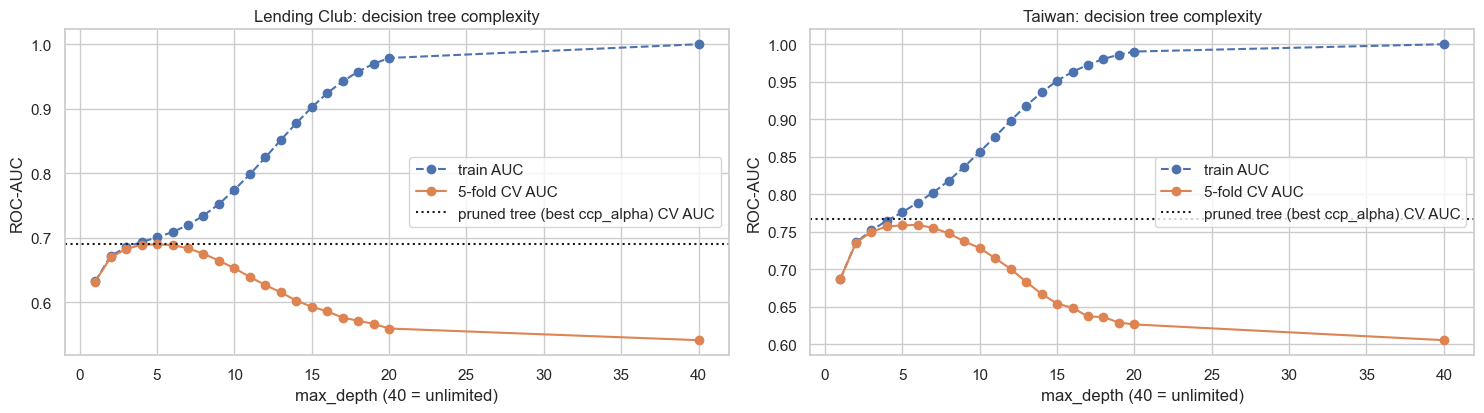

In [7]:
dt_best = {}
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    prep = make_prep(num, cat).fit(Xa); Za = prep.transform(Xa)
    path = DecisionTreeClassifier(class_weight="balanced", random_state=SEED, min_samples_leaf=5).cost_complexity_pruning_path(Za, ya)
    alphas = np.logspace(-5, -2, 16)  # log-spaced so both lightly and heavily pruned trees are tried
    print(f"{name}: full pruning path has {len(path.ccp_alphas)} alphas (max {path.ccp_alphas.max():.2e}); searching 16 log-spaced values 1e-5..1e-2")
    pipe = Pipeline([("prep", make_prep(num, cat)), ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=SEED, min_samples_leaf=5))])
    gs = GridSearchCV(pipe, {"clf__ccp_alpha": alphas}, scoring="roc_auc", cv=CV5, n_jobs=-1).fit(Xa, ya)
    tree = gs.best_estimator_.named_steps["clf"]
    dt_best[name] = gs
    cvp = pd.DataFrame(gs.cv_results_)[["param_clf__ccp_alpha", "mean_test_score", "std_test_score"]]
    print("   CV AUC by ccp_alpha:", ", ".join(f"{a:.0e}:{m:.4f}" for a, m in zip(cvp.param_clf__ccp_alpha.astype(float), cvp.mean_test_score)))
    print(f"   best ccp_alpha={gs.best_params_['clf__ccp_alpha']:.2e} "
          f"CV AUC={gs.best_score_:.4f} | leaves={tree.get_n_leaves()} depth={tree.get_depth()}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for ax, name in zip(axes, DATA):
    c = dt_curves[name]
    ax.plot(c.max_depth, c.train_auc, "o--", label="train AUC"); ax.plot(c.max_depth, c.cv_auc, "o-", label="5-fold CV AUC")
    ax.axhline(dt_best[name].best_score_, color="k", ls=":", label="pruned tree (best ccp_alpha) CV AUC")
    ax.set_xlabel("max_depth (40 = unlimited)"); ax.set_ylabel("ROC-AUC"); ax.set_title(f"{name}: decision tree complexity"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w6_tree_depth.png", dpi=150, bbox_inches="tight"); plt.show()

### Pruning Findings

* **Path sizes:** the full pruning path has 2,794 (Lending Club) and 1,372 (Taiwan) distinct α values.
* **Lending Club.** CV AUC rises from 0.578 at α = 10⁻⁵ (barely pruned, overfit) to a peak of 0.6907 at α = 2.5e-4, then falls to 0.632 at α = 10⁻². Best tree has 24 leaves and depth 7.
* **Taiwan.** CV AUC goes 0.669 → peak 0.7675 at α = 6.3e-4 → 0.690. Best tree has 19 leaves and depth 8.
* **Plot.** The dotted "pruned tree" line sits at or slightly above the best `max_depth` point on both datasets.

Pruning works. It produces a small tree (19–24 leaves) that matches or beats the best depth-limited tree: 0.6907 vs 0.6898 on Lending Club, and 0.7675 vs 0.7594 on Taiwan. Pruning can keep a deep branch where it helps and cut shallow branches elsewhere, which a single global `max_depth` cannot do. The CV curves have an interior peak on both sides, confirming the α grid covered the right range.

### 5. A Readable Depth-3 Tree for Each Dataset

The main business advantage of a single tree is that it can be read as rules. A depth-3 tree (at most 8 leaves) is shallow enough to explain to a credit committee, so this step inspects which splits each dataset's tree chooses first — the root split (the single most informative feature/threshold) and the default rate in the riskiest and safest leaves.

Lending Club: root split = int_rate <= 14.395; depth-3 tree test AUC = 0.6887
Taiwan: root split = PAY_1 <= 1.500; depth-3 tree test AUC = 0.7234


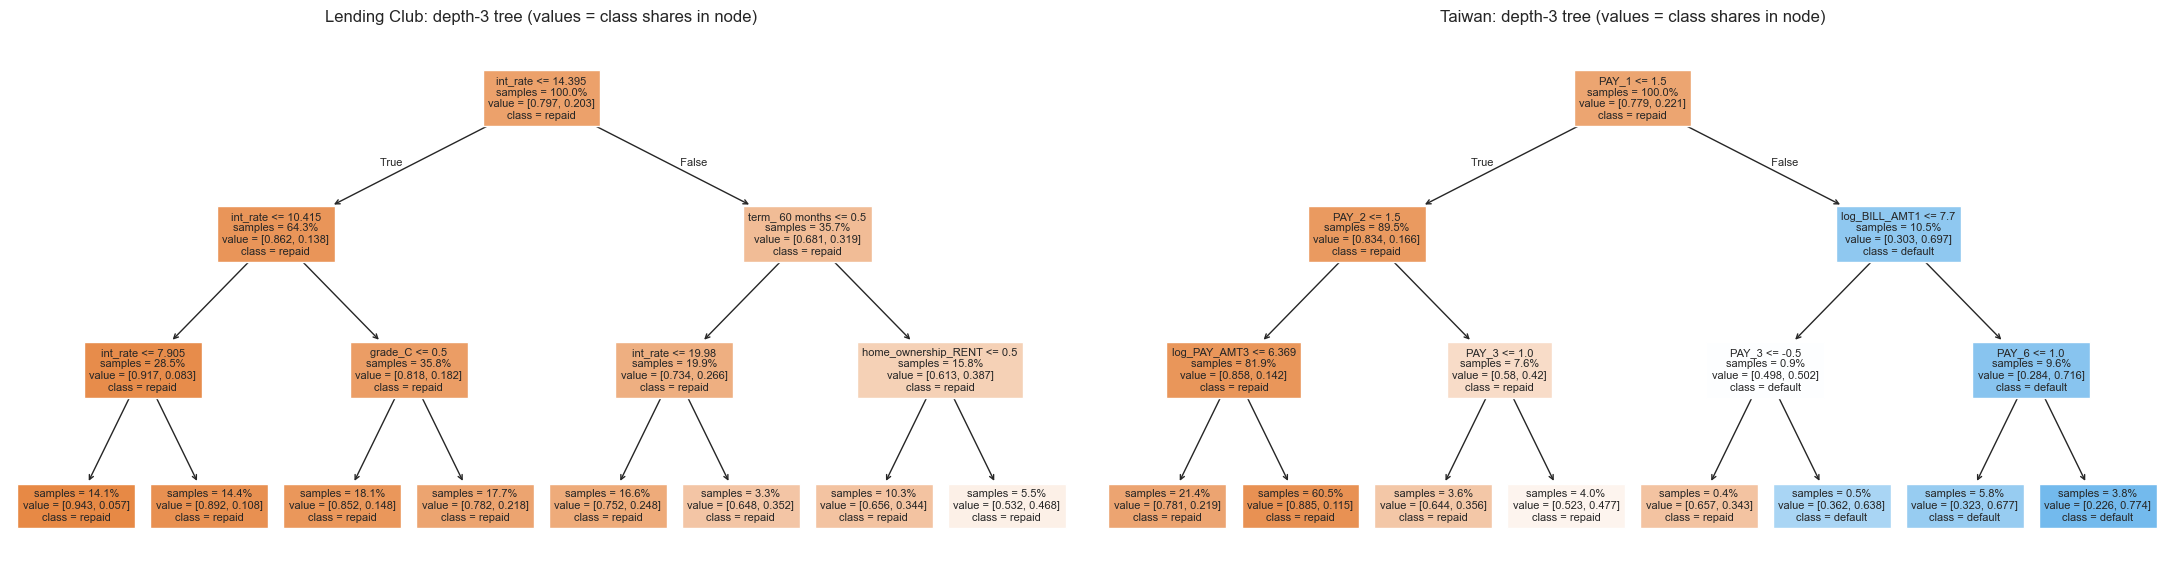

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(22, 6))
for ax, (name, (Xa, Xb, ya, yb, num, cat)) in zip(axes, DATA.items()):
    prep = make_prep(num, cat, scale=False).fit(Xa)
    small = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(prep.transform(Xa), ya)
    fn = [f.replace("num__", "").replace("cat__", "") for f in prep.get_feature_names_out()]
    plot_tree(small, feature_names=fn, class_names=["repaid", "default"], filled=True, proportion=True, impurity=False, fontsize=8, ax=ax)
    ax.set_title(f"{name}: depth-3 tree (values = class shares in node)")
    Zb = prep.transform(Xb); leaf_auc = roc_auc_score(yb, small.predict_proba(Zb)[:, 1])
    print(f"{name}: root split = {fn[small.tree_.feature[0]]} <= {small.tree_.threshold[0]:.3f}; depth-3 tree test AUC = {leaf_auc:.4f}")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w6_tree_depth3.png", dpi=130, bbox_inches="tight"); plt.show()

### Depth-3 Tree Findings

**Lending Club.**

* Root split: `int_rate ≤ 14.395%`. 64% of loans fall on the low-rate side at about a 14% default rate; the 36% above it default at about 32%.
* Next splits are lower rate cut-offs on the left, and `term = 60 months` then `home_ownership = RENT` on the right. The riskiest leaf (high rate, 60-month term, renter — 5.5% of loans) defaults at about 47%.
* Test AUC of this 8-leaf tree: 0.6887.

**Taiwan.**

* Root split: `PAY_1 ≤ 1.5`. The 10.5% of clients who are 2+ months late on the latest bill default at about 70%, compared with about 17% for everyone else.
* Further splits use `PAY_2`, the latest bill (`log_BILL_AMT1`), and older PAY months.
* Test AUC: 0.7234.

**Business reading.** On Lending Club the interest rate (which encodes the lender's own grade) is the single strongest risk signal; loan length and housing add to it. On Taiwan recent delinquency dominates — a one-rule policy ("flag anyone 2+ months late") already isolates a group with about a 70% default rate.

For a credit committee, a depth-3 tree reaches about 97% of the full tuned tree's AUC on both datasets (0.689 vs 0.701; 0.723 vs 0.755) with rules a committee can read directly.

### 6. Random Forest — `RandomizedSearchCV` (Depth Model)

A random forest has several interacting hyperparameters, and a full grid would need hundreds of combinations × 5 folds. `RandomizedSearchCV` samples 20 combinations from the ranges below. Research (Bergstra & Bengio, 2012) shows random search usually finds near-optimal settings far faster, because only a few hyperparameters really matter.

| Hyperparameter | Values | What it controls |
|---|---|---|
| `n_estimators` | 150, 300 | Number of trees — more trees mean lower variance with diminishing returns |
| `max_depth` | 8, 12, 16, None | Depth of each tree — the main bias–variance knob |
| `min_samples_leaf` | 5, 20, 50, 100 | Smallest leaf — larger values give smoother probabilities and less memorization |
| `max_features` | sqrt, 0.3 | Features tried per split — smaller fractions produce more decorrelated trees |
| `class_weight` | balanced, balanced_subsample | Reweights defaults either per forest or per bootstrap sample |

A test fit with 600 trees, unlimited depth, 1-row leaves, and 50% of features took over 5 minutes per fit. Those extreme settings are excluded from the random grid; small leaves (down to 2) and deep trees (up to depth 24) are instead examined separately in the validation curves below.

Scoring is 5-fold stratified CV ROC-AUC on the full training set (48,000 and 23,972 rows). Trees run in parallel (`n_jobs=-1`), and `return_train_score=True` records the train–validation gap.

In [9]:
rf_space = {"clf__n_estimators": [150, 300], "clf__max_depth": [8, 12, 16, None],
            "clf__min_samples_leaf": [5, 20, 50, 100], "clf__max_features": ["sqrt", 0.3],
            "clf__class_weight": ["balanced", "balanced_subsample"]}
rf_rs = {}
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    pipe = Pipeline([("prep", make_prep(num, cat)), ("clf", RandomForestClassifier(random_state=SEED, n_jobs=1))])
    t0 = time.time()
    rs = RandomizedSearchCV(pipe, rf_space, n_iter=20, scoring="roc_auc", cv=CV5, n_jobs=-1, random_state=SEED,
                            return_train_score=True).fit(Xa, ya)
    rf_rs[name] = rs
    r = pd.DataFrame(rs.cv_results_); r["gap"] = r.mean_train_score - r.mean_test_score
    cols = ["param_clf__n_estimators", "param_clf__max_depth", "param_clf__min_samples_leaf", "param_clf__max_features",
            "param_clf__class_weight", "mean_train_score", "mean_test_score", "std_test_score", "gap"]
    print(f"\n{name}: search {time.time()-t0:.0f}s | BEST {rs.best_params_} | CV AUC {rs.best_score_:.4f} +- {r.loc[rs.best_index_, 'std_test_score']:.4f}")
    display(r.sort_values("rank_test_score")[cols].head(5).round(4))
    print("Largest train-CV gaps:"); display(r.sort_values("gap", ascending=False)[cols].head(2).round(4))


Lending Club: search 155s | BEST {'clf__n_estimators': 300, 'clf__min_samples_leaf': 20, 'clf__max_features': 'sqrt', 'clf__max_depth': 12, 'clf__class_weight': 'balanced'} | CV AUC 0.7047 +- 0.0049


,param_clf__n_estimators,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__max_features,param_clf__class_weight,mean_train_score,mean_test_score,std_test_score,gap
2,300,12,20,sqrt,balanced,0.7652,0.7047,0.0049,0.0605
18,300,None,50,0.3,balanced_subsample,0.7687,0.7042,0.0049,0.0645
4,150,16,20,sqrt,balanced_subsample,0.7921,0.7042,0.0051,0.0879
10,150,12,100,0.3,balanced_subsample,0.7355,0.7041,0.0051,0.0314
3,300,12,100,0.3,balanced,0.7325,0.7041,0.0049,0.0283


Largest train-CV gaps:


,param_clf__n_estimators,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__max_features,param_clf__class_weight,mean_train_score,mean_test_score,std_test_score,gap
5,150,None,5,0.3,balanced,0.9842,0.6967,0.0042,0.2875
15,300,None,5,sqrt,balanced_subsample,0.9492,0.7011,0.0045,0.2481



Taiwan: search 128s | BEST {'clf__n_estimators': 300, 'clf__min_samples_leaf': 50, 'clf__max_features': 0.3, 'clf__max_depth': None, 'clf__class_weight': 'balanced_subsample'} | CV AUC 0.7864 +- 0.0077


,param_clf__n_estimators,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__max_features,param_clf__class_weight,mean_train_score,mean_test_score,std_test_score,gap
18,300,None,50,0.3,balanced_subsample,0.8481,0.7864,0.0077,0.0617
2,300,12,20,sqrt,balanced,0.8593,0.7856,0.0085,0.0737
11,300,12,20,0.3,balanced,0.8655,0.7856,0.0082,0.0799
16,150,16,50,sqrt,balanced,0.8366,0.7854,0.0083,0.0512
9,150,12,20,0.3,balanced,0.8650,0.7854,0.0081,0.0796


Largest train-CV gaps:


,param_clf__n_estimators,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__max_features,param_clf__class_weight,mean_train_score,mean_test_score,std_test_score,gap
5,150,None,5,0.3,balanced,0.9793,0.7791,0.0084,0.2002
15,300,None,5,sqrt,balanced_subsample,0.9714,0.7804,0.0079,0.1910


### Random Forest Random-Search Findings

**Lending Club (41 s).**

* Best: 300 trees, `max_depth = 12`, `min_samples_leaf = 20`, `max_features = sqrt`, `class_weight = balanced`, with CV AUC 0.7047 ± 0.0049.
* The top 5 candidates sit between 0.7041 and 0.7047 (well within one SD) despite quite different settings.
* Train–CV gap of the best model: 0.061.
* Most overfit: unlimited depth with 5-row leaves, at train 0.984 vs CV 0.697 (gap 0.29).

**Taiwan (37 s).**

* Best: 300 trees, `max_depth = None`, `min_samples_leaf = 50`, `max_features = 0.3`, `class_weight = balanced_subsample`, with CV AUC 0.7864 ± 0.0077.
* Top 5 span 0.7854–0.7864. Gap of the best model: 0.062.
* Most overfit: unlimited depth with 5-row leaves, at train 0.979 vs CV 0.779 (gap 0.20).

Three readings:

* **The winners are regularized in different ways.** On Lending Club it is the depth limit (12) plus 20-row leaves; on Taiwan it is large leaves (50) with unlimited depth. Both stop individual trees from memorizing.
* **Averaging protects against overfitting.** Even the most overfit forest loses only about 0.008 AUC on CV relative to the best, whereas a single unlimited tree lost about 0.15. This is the core benefit of bagging and random feature subsets.
* **Taiwan improves on every earlier model; Lending Club stays flat.** Taiwan CV AUC 0.786 against logistic regression 0.752, the best SVM 0.762, and the pruned tree 0.768. Lending Club's 0.705 is level with logistic regression (0.703).

### 7. Depth Analysis — Validation Curves for `min_samples_leaf` and `max_depth`, Plus OOB

Random search tells us *which* setting wins; validation curves tell us *why*. Holding the other best parameters fixed, each knob is varied one at a time and train vs CV AUC is plotted. The best forest is also refit with `oob_score=True` to compare the out-of-bag estimate with the CV estimate.

Lending Club min_samples_leaf: best 20 CV 0.7045 (train 0.7644) | at 2: train 0.8319 CV 0.7030
Lending Club max_depth: best 12 CV 0.7045 (train 0.7644) | at 2: train 0.6916 CV 0.6894
Lending Club: OOB AUC 0.7029 vs 5-fold CV AUC 0.7047
Taiwan min_samples_leaf: best 50 CV 0.7859 (train 0.8476) | at 2: train 0.9990 CV 0.7735
Taiwan max_depth: best 24 CV 0.7859 (train 0.8476) | at 2: train 0.7691 CV 0.7669
Taiwan: OOB AUC 0.7864 vs 5-fold CV AUC 0.7864


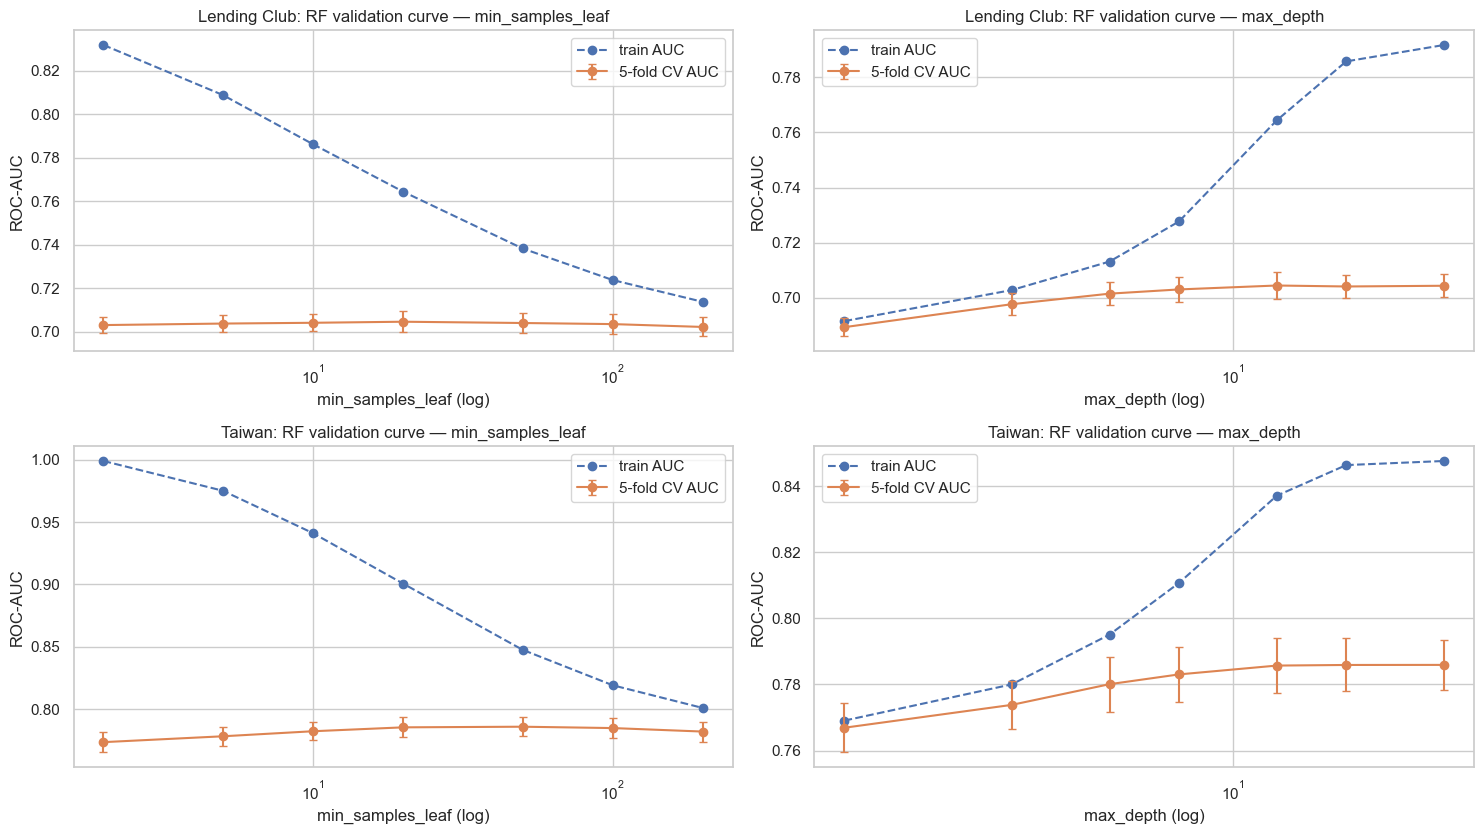

In [10]:
from sklearn.model_selection import validation_curve
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
rf_oob = {}
for row, (name, (Xa, Xb, ya, yb, num, cat)) in enumerate(DATA.items()):
    best = rf_rs[name].best_estimator_
    base = Pipeline([("prep", make_prep(num, cat)), ("clf", RandomForestClassifier(**{**best.named_steps["clf"].get_params(), "n_estimators": 150, "n_jobs": 1}))])
    for col, (pname, vals, lab) in enumerate([("clf__min_samples_leaf", [2, 5, 10, 20, 50, 100, 200], "min_samples_leaf"),
                                              ("clf__max_depth", [2, 4, 6, 8, 12, 16, 24], "max_depth")]):
        tr, va = validation_curve(base, Xa, ya, param_name=pname, param_range=vals, cv=CV5, scoring="roc_auc", n_jobs=-1)
        ax = axes[row, col]
        ax.plot(vals, tr.mean(1), "o--", label="train AUC"); ax.errorbar(vals, va.mean(1), yerr=va.std(1), fmt="o-", capsize=3, label="5-fold CV AUC")
        ax.set_xscale("log"); ax.set_xlabel(lab + " (log)"); ax.set_ylabel("ROC-AUC"); ax.set_title(f"{name}: RF validation curve — {lab}"); ax.legend()
        i = int(np.argmax(va.mean(1)))
        print(f"{name} {lab}: best {vals[i]} CV {va.mean(1)[i]:.4f} (train {tr.mean(1)[i]:.4f}) | at {vals[0]}: train {tr.mean(1)[0]:.4f} CV {va.mean(1)[0]:.4f}")
    oob = RandomForestClassifier(**{**best.named_steps["clf"].get_params(), "oob_score": True, "n_jobs": -1})
    Za = make_prep(num, cat).fit(Xa).transform(Xa)
    oob.fit(Za, ya); rf_oob[name] = roc_auc_score(ya, oob.oob_decision_function_[:, 1])
    print(f"{name}: OOB AUC {rf_oob[name]:.4f} vs 5-fold CV AUC {rf_rs[name].best_score_:.4f}")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w6_rf_validation.png", dpi=150, bbox_inches="tight"); plt.show()

### Validation-Curve and OOB Findings

**`min_samples_leaf` (left panels).**

* As leaves shrink to 2, train AUC rises to 0.832 (Lending Club) and 0.999 (Taiwan).
* CV AUC stays almost flat: Lending Club 0.703–0.705, peaking at 20; Taiwan 0.774–0.786, peaking at 50.

**`max_depth` (right panels).**

* At depth 2, CV AUC is 0.689 / 0.767 (underfit).
* It rises to a plateau from about depth 8–12 onward: Lending Club best at 12 (0.7045), Taiwan best at 24 (0.7859), essentially flat after depth 12.
* Train AUC keeps rising (0.79 / 0.85).

**OOB vs CV.**

* Lending Club: OOB 0.7029 vs CV 0.7047.
* Taiwan: OOB 0.7864 vs CV 0.7864.

Three readings:

* **Bias–variance in context.** The bias side is only visible at very shallow depth. The variance side shows up as the widening train–CV gap, but the forest's averaging keeps that gap from damaging validation performance, which is why random forests are forgiving to tune. Taiwan gains about 0.012 AUC from larger leaves because its smaller sample is noisier per leaf.
* **OOB works as a free validation set.** It agrees with 5-fold CV to within 0.002, so a forest's generalization can be checked without a holdout, using the 37% of rows each tree never saw.
* **Flat plateaus.** The CV error bars (±1 SD across folds) overlap across most of each plateau, so any setting inside the plateau is statistically equivalent.

### 8. Feature Importance — Impurity-Based vs Permutation (Test Set)

* **Impurity importance** is the total Gini decrease contributed by each feature across all trees. It is fast but biased toward continuous or high-cardinality features, which offer more possible split points.
* **Permutation importance** is the drop in test AUC when one feature's values are shuffled. It is slower but measures real predictive reliance on unseen data, and it is computed on the *original* columns, so a categorical variable is scored as a whole.

Comparing the two guards against over-reading either one. What to look for: top features under each method, where they agree or disagree, and how the rankings relate to the EDA (grade and `int_rate` for Lending Club; `PAY_1` for Taiwan).


Lending Club — top 8 impurity importance:
int_rate           0.3398
term_ 60 months    0.1075
dti                0.0962
log_annual_inc     0.0637
revol_util         0.0584
loan_amnt          0.0569
grade_B            0.0450
grade_E            0.0385
Lending Club — top 8 permutation importance (mean test-AUC drop +- sd):
                auc_drop      sd
int_rate          0.0684  0.0038
grade             0.0178  0.0010
term              0.0121  0.0007
dti               0.0060  0.0018
home_ownership    0.0049  0.0002
log_annual_inc    0.0035  0.0006
loan_amnt         0.0028  0.0006
purpose           0.0007  0.0004

Taiwan — top 8 impurity importance:
PAY_1            0.2942
PAY_2            0.1151
PAY_3            0.0691
PAY_4            0.0543
log_LIMIT_BAL    0.0449
log_BILL_AMT1    0.0432
log_PAY_AMT1     0.0425
log_PAY_AMT2     0.0378
Taiwan — top 8 permutation importance (mean test-AUC drop +- sd):
               auc_drop      sd
PAY_1            0.0759  0.0059
log_LIMIT_BAL    0.01

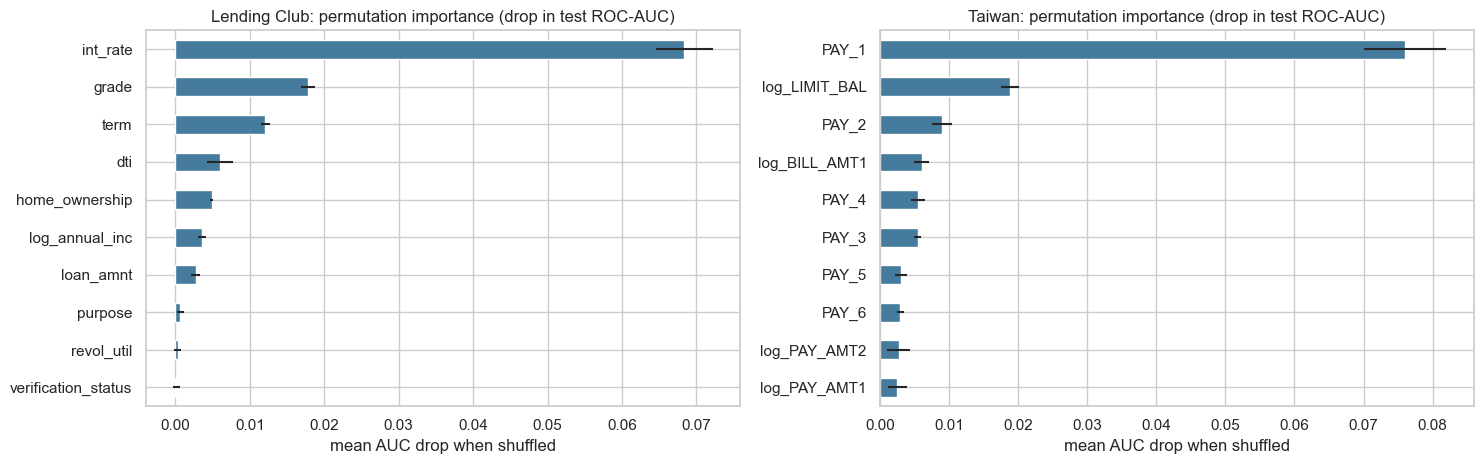

In [11]:
imp = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, (name, (Xa, Xb, ya, yb, num, cat)) in zip(axes, DATA.items()):
    best = rf_rs[name].best_estimator_
    names = [f.replace("num__", "").replace("cat__", "") for f in best.named_steps["prep"].get_feature_names_out()]
    gini = pd.Series(best.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
    pi = permutation_importance(best, Xb, yb, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
    perm = pd.Series(pi.importances_mean, index=Xb.columns).sort_values(ascending=False)
    imp[name] = (gini, perm, pd.Series(pi.importances_std, index=Xb.columns))
    print(f"\n{name} — top 8 impurity importance:"); print(gini.head(8).round(4).to_string())
    print(f"{name} — top 8 permutation importance (mean test-AUC drop +- sd):")
    print(pd.DataFrame({"auc_drop": perm.head(8), "sd": imp[name][2][perm.head(8).index]}).round(4).to_string())
    perm.head(10)[::-1].plot.barh(ax=ax, xerr=imp[name][2][perm.head(10).index[::-1]], color="#457b9d")
    ax.set_title(f"{name}: permutation importance (drop in test ROC-AUC)"); ax.set_xlabel("mean AUC drop when shuffled")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w6_rf_importance.png", dpi=150, bbox_inches="tight"); plt.show()

### Feature-Importance Findings

**Lending Club.**

* Impurity: `int_rate` 0.340, `term_60` 0.108, `dti` 0.096, `log_annual_inc` 0.064, `revol_util` 0.058, `loan_amnt` 0.057, then grade dummies.
* Permutation (test AUC drop):
  * `int_rate` 0.068 ± 0.004
  * `grade` 0.018
  * `term` 0.012
  * `dti` 0.006
  * `home_ownership` 0.005
  * `log_annual_inc` 0.004
  * `loan_amnt` 0.003
  * `purpose` 0.001

**Taiwan.**

* Impurity: `PAY_1` 0.294, `PAY_2` 0.115, `PAY_3` 0.069, `PAY_4` 0.054, `log_LIMIT_BAL` 0.045, `log_BILL_AMT1` 0.043.
* Permutation:
  * `PAY_1` 0.076 ± 0.006
  * `log_LIMIT_BAL` 0.019
  * `PAY_2` 0.009
  * `log_BILL_AMT1` 0.006
  * `PAY_3`–`PAY_6` 0.003–0.006

Four readings:

* **The two methods agree on the leader.** `int_rate` and `PAY_1` are first under both, and by a wide margin — shuffling either one alone costs about 0.07 AUC.
* **They disagree on the second tier, as theory predicts.** Impurity inflates continuous features: it ranks `dti`, income and `revol_util` above `grade` because continuous features offer many split points. Permutation (on held-out data, scoring `grade` as a whole) puts `grade` and `term` ahead of them.
* **Correlated features share credit.** On Taiwan, impurity spreads importance over `PAY_2`–`PAY_4`. Permutation shows that once `PAY_1` is known the older months add little, because a correlated feature can stand in when one is shuffled.
* **`log_LIMIT_BAL` rises to #2 under permutation.** The bank's own limit decision carries risk information in its own right.

**Domain reading.** On Lending Club, risk is mostly *priced* (`int_rate` and grade are the lender's own risk assessment) with loan structure (`term`) in second place. On Taiwan, risk is mostly *behavioural*: the most recent repayment status is the strongest early-warning signal.

A high `int_rate` does not cause default — partly the reverse holds, since riskier borrowers are priced higher, although high payments can add some burden. These are measures of predictive reliance within this model, not causal effects.

### 9. Threshold Choice for the Forest (Out-of-Fold) and Held-Out Test Metrics

The decision threshold is chosen to maximize F1 on out-of-fold training predictions and then applied once to the test set. Choosing the threshold on the test set would be leakage, and the test score would be optimistic.

In [12]:
rf_test = {}
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    best = rf_rs[name].best_estimator_
    oof = cross_val_predict(best, Xa, ya, cv=CV5, method="predict_proba", n_jobs=-1)[:, 1]
    p, r, th = precision_recall_curve(ya, oof); f1s = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-9, None)
    thr = float(th[np.argmax(f1s)]); prob = best.predict_proba(Xb)[:, 1]
    rf_test[name] = (prob, thr)
    print(f"\n{name}: OOF F1-optimal threshold {thr:.3f}")
    display(pd.DataFrame({"at 0.5": scores(yb, prob, 0.5), f"at {thr:.3f}": scores(yb, prob, thr)}).T.round(4))
    print("Confusion matrix at tuned threshold [[TN FP] [FN TP]]:", confusion_matrix(yb, (prob >= thr).astype(int)).tolist())


Lending Club: OOF F1-optimal threshold 0.495


,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
at 0.5,0.6480,0.3216,0.6620,0.4329,0.7099,0.3801,0.5000
at 0.495,0.6422,0.3191,0.6735,0.4331,0.7099,0.3801,0.4952


Confusion matrix at tuned threshold [[TN FP] [FN TP]]: [[6066, 3499], [795, 1640]]

Taiwan: OOF F1-optimal threshold 0.543


,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
at 0.5,0.7686,0.4814,0.5950,0.5322,0.7733,0.5507,0.5000
at 0.543,0.7837,0.5104,0.5535,0.5311,0.7733,0.5507,0.5428


Confusion matrix at tuned threshold [[TN FP] [FN TP]]: [[3963, 704], [592, 734]]


### Threshold Findings

**Lending Club.**

* Test ROC-AUC 0.7099, PR-AUC 0.3801. Out-of-fold threshold: 0.495.
* At that threshold: precision 0.319, recall 0.674, F1 0.433.
* Confusion matrix: TN 6,066, FP 3,499, FN 795, TP 1,640.

**Taiwan.**

* Test ROC-AUC 0.7733, PR-AUC 0.5507. Threshold: 0.543.
* At that threshold: precision 0.510, recall 0.554, F1 0.531, accuracy 0.784.
* Confusion matrix: TN 3,963, FP 704, FN 592, TP 734.

The test scores sit close to the CV estimates. Lending Club tests at 0.710 against CV 0.705, and Taiwan at 0.773 against CV 0.786. The Taiwan drop of 0.013 is within about 1.7 fold-SDs, so the tuning did not overfit the validation folds.

Taiwan PR-AUC of 0.551 is 2.5× the random baseline of 0.221, the best of any model fit so far. Balanced class weights already put the F1 optimum near 0.5, so moving the cutoff changes the precision/recall mix rather than F1.

### 10. Final Cross-Model Comparison on the Shared Test Sets

This is the apples-to-apples table that pulls the best model from each prior analysis onto the same held-out test set:

* **Logistic regression:** balanced class weights, with the best `C` and penalty from the earlier CV grid.
* **SVM:** the best kernel, `C`, and γ from the earlier grid, fit on the 6,000-row stratified subsample.
* **Decision tree:** pruned at the best `ccp_alpha` from this analysis.
* **Random forest:** the best settings from this analysis's random search.

Thresholds for the logistic model, decision tree, and random forest are chosen on out-of-fold training predictions. The SVM uses its own decision-function boundary (score 0).

,dataset,model,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
0,Lending Club,Logistic regression (W4),0.6527,0.3236,0.6530,0.4328,0.7126,0.3782,0.5098
1,Lending Club,"Decision tree, pruned (W6)",0.6060,0.3009,0.7113,0.4229,0.7006,0.3531,0.4604
2,Lending Club,"Random forest, tuned (W6)",0.6422,0.3191,0.6735,0.4331,0.7099,0.3801,0.4952
3,Lending Club,"RBF SVM, tuned (W5, 6k rows)",0.6769,0.3357,0.6049,0.4318,0.7014,0.3627,0.0000
4,Taiwan,Logistic regression (W4),0.7586,0.4629,0.5694,0.5107,0.7410,0.4993,0.5396
5,Taiwan,"Decision tree, pruned (W6)",0.7724,0.4872,0.5460,0.5149,0.7545,0.4923,0.5756
6,Taiwan,"Random forest, tuned (W6)",0.7837,0.5104,0.5535,0.5311,0.7733,0.5507,0.5428
7,Taiwan,"RBF SVM, tuned (W5, 6k rows)",0.7492,0.4496,0.5950,0.5122,0.7443,0.4890,0.0000


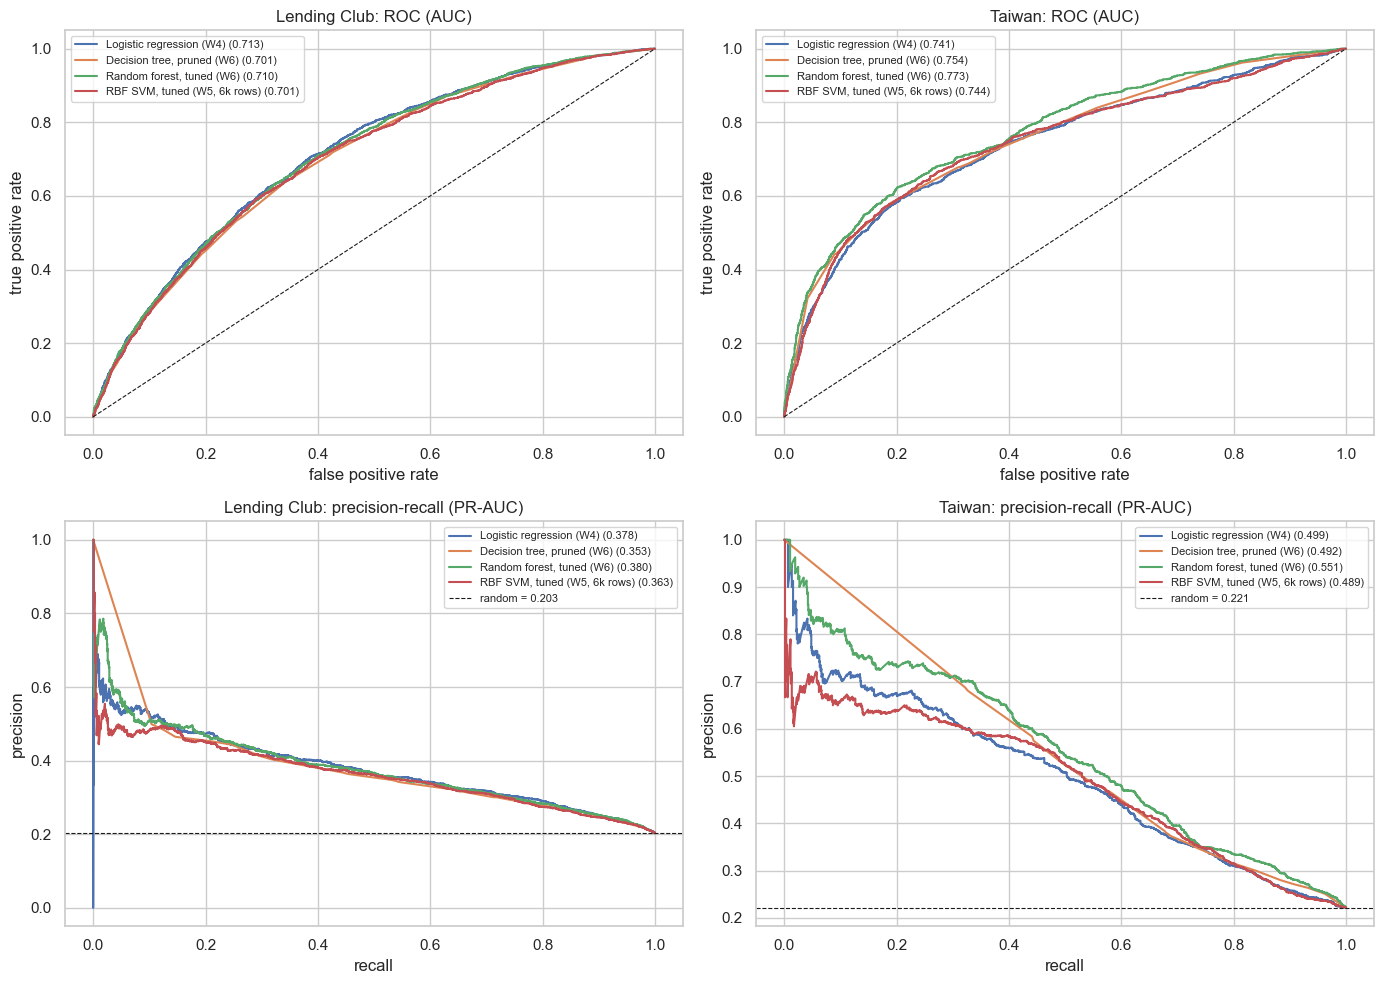

In [13]:
W4_BEST = {"Lending Club": {"C": 1, "penalty": "l1"}, "Taiwan": {"C": 0.001, "penalty": "l2"}}
W5_BEST = {"Lending Club": {"kernel": "rbf", "C": 0.1, "gamma": 0.01}, "Taiwan": {"kernel": "rbf", "C": 1, "gamma": 0.01}}
def oof_thr(est, Xa, ya):
    oof = cross_val_predict(est, Xa, ya, cv=CV5, method="predict_proba", n_jobs=-1)[:, 1]
    p, r, th = precision_recall_curve(ya, oof); f1s = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-9, None)
    return float(th[np.argmax(f1s)])
final_rows, curves = [], {}
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    lr = Pipeline([("prep", make_prep(num, cat)), ("clf", LogisticRegression(solver="liblinear", class_weight="balanced", max_iter=2000, **W4_BEST[name]))]).fit(Xa, ya)
    Xs, _, ys, _ = train_test_split(Xa, ya, train_size=6000, stratify=ya, random_state=SEED)
    svm = Pipeline([("prep", make_prep(num, cat)), ("clf", SVC(class_weight="balanced", **W5_BEST[name]))]).fit(Xs, ys)
    dt = dt_best[name].best_estimator_; rf = rf_rs[name].best_estimator_
    models = {"Logistic regression (W4)": (lr, oof_thr(lr, Xa, ya)), "Decision tree, pruned (W6)": (dt, oof_thr(dt, Xa, ya)),
              "Random forest, tuned (W6)": (rf, rf_test[name][1])}
    curves[name] = {}
    for mname, (m, thr) in models.items():
        prob = m.predict_proba(Xb)[:, 1]; curves[name][mname] = prob
        final_rows.append({"dataset": name, "model": mname, **scores(yb, prob, thr)})
    sc = svm.decision_function(Xb); pred = (sc >= 0).astype(int); curves[name]["RBF SVM, tuned (W5, 6k rows)"] = sc
    final_rows.append({"dataset": name, "model": "RBF SVM, tuned (W5, 6k rows)", "accuracy": accuracy_score(yb, pred), "precision": precision_score(yb, pred),
                       "recall": recall_score(yb, pred), "f1": f1_score(yb, pred), "roc_auc": roc_auc_score(yb, sc),
                       "pr_auc": average_precision_score(yb, sc), "threshold": 0.0})
final = pd.DataFrame(final_rows)
display(final.round(4))
final.round(4).to_csv(f"{FIG}/table_final_model_comparison.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for col, (name, (Xa, Xb, ya, yb, num, cat)) in enumerate(DATA.items()):
    for mname, s in curves[name].items():
        f_, t_, _ = roc_curve(yb, s); axes[0, col].plot(f_, t_, label=f"{mname} ({roc_auc_score(yb, s):.3f})")
        p_, r_, _ = precision_recall_curve(yb, s); axes[1, col].plot(r_, p_, label=f"{mname} ({average_precision_score(yb, s):.3f})")
    axes[0, col].plot([0, 1], [0, 1], "k--", lw=.8); axes[0, col].set(xlabel="false positive rate", ylabel="true positive rate", title=f"{name}: ROC (AUC)")
    axes[1, col].axhline(yb.mean(), color="k", ls="--", lw=.8, label=f"random = {yb.mean():.3f}")
    axes[1, col].set(xlabel="recall", ylabel="precision", title=f"{name}: precision-recall (PR-AUC)")
    axes[0, col].legend(fontsize=8); axes[1, col].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w6_roc_pr_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

### 12. Paired Bootstrap 95% CI on Test ROC-AUC + PR-AUC
<!-- execute this block -->

The final comparison table [cell 31] reports point estimates: the four-model LC spread is 0.012 ROC-AUC and the TW RF-vs-DT gap is +0.019. On test sets of 12,000 (LC) and 5,993 (TW) rows both figures are plausibly inside sampling noise. The paired bootstrap below resamples the **same** test rows 200 times, re-scores every model on each resample, and reports 95% CIs on every pairwise delta so the "wins" in [cell 31] can be read with uncertainty attached.


In [14]:
# Paired bootstrap on the held-out test set.
# Reuses `curves[name]` scores (predict_proba / decision_function) that were
# computed in cell [31] on the original test rows -- no refits needed.
rng = np.random.default_rng(SEED)
N_BOOT = 200

boot_rows = []
for name, (_, Xb, _, yb, _, _) in DATA.items():
    y = yb.to_numpy()
    n = len(y)
    model_scores = {m: np.asarray(s) for m, s in curves[name].items()}
    # auc/pr-auc per bootstrap sample
    samples = {m: {"roc": np.empty(N_BOOT), "pr": np.empty(N_BOOT)} for m in model_scores}
    for b in range(N_BOOT):
        idx = rng.integers(0, n, n)
        yb_b = y[idx]
        if yb_b.sum() == 0 or yb_b.sum() == n:
            continue
        for m, s in model_scores.items():
            s_b = s[idx]
            samples[m]["roc"][b] = roc_auc_score(yb_b, s_b)
            samples[m]["pr"][b] = average_precision_score(yb_b, s_b)
    # headline CIs
    for m in model_scores:
        lo_r, hi_r = np.percentile(samples[m]["roc"], [2.5, 97.5])
        lo_p, hi_p = np.percentile(samples[m]["pr"], [2.5, 97.5])
        boot_rows.append({"dataset": name, "model": m,
                          "roc_auc_lo": lo_r, "roc_auc_hi": hi_r,
                          "pr_auc_lo": lo_p, "pr_auc_hi": hi_p})
    # pairwise deltas vs Random Forest
    print(f"\n{name}: paired-bootstrap 95% CI on ROC-AUC delta vs Random Forest")
    rf_key = "Random forest, tuned (W6)"
    rows = []
    for m in model_scores:
        if m == rf_key: continue
        d_roc = samples[m]["roc"] - samples[rf_key]["roc"]
        d_pr  = samples[m]["pr"]  - samples[rf_key]["pr"]
        rows.append({"model": m,
                     "ROC_auc_delta": d_roc.mean(),
                     "ROC_2.5%": np.percentile(d_roc, 2.5),
                     "ROC_97.5%": np.percentile(d_roc, 97.5),
                     "PR_auc_delta": d_pr.mean(),
                     "PR_2.5%": np.percentile(d_pr, 2.5),
                     "PR_97.5%": np.percentile(d_pr, 97.5)})
    display(pd.DataFrame(rows).round(4))

print("\nPer-model 95% CI on test metrics:")
display(pd.DataFrame(boot_rows).round(4))



Lending Club: paired-bootstrap 95% CI on ROC-AUC delta vs Random Forest


,model,ROC_auc_delta,ROC_2.5%,ROC_97.5%,PR_auc_delta,PR_2.5%,PR_97.5%
0,Logistic regression (W4),0.0027,-0.0002,0.0059,-0.0018,-0.0097,0.0057
1,"Decision tree, pruned (W6)",-0.0096,-0.0139,-0.0059,-0.0278,-0.0363,-0.0197
2,"RBF SVM, tuned (W5, 6k rows)",-0.0087,-0.0118,-0.0050,-0.0178,-0.0265,-0.0101



Taiwan: paired-bootstrap 95% CI on ROC-AUC delta vs Random Forest


,model,ROC_auc_delta,ROC_2.5%,ROC_97.5%,PR_auc_delta,PR_2.5%,PR_97.5%
0,Logistic regression (W4),-0.0324,-0.0409,-0.0232,-0.0516,-0.0672,-0.0388
1,"Decision tree, pruned (W6)",-0.0189,-0.0255,-0.0111,-0.0577,-0.0703,-0.0444
2,"RBF SVM, tuned (W5, 6k rows)",-0.0290,-0.0370,-0.0207,-0.0603,-0.0759,-0.0447



Per-model 95% CI on test metrics:


,dataset,model,roc_auc_lo,roc_auc_hi,pr_auc_lo,pr_auc_hi
0,Lending Club,Logistic regression (W4),0.7019,0.7226,0.3594,0.3950
1,Lending Club,"Decision tree, pruned (W6)",0.6895,0.7106,0.3349,0.3667
2,Lending Club,"Random forest, tuned (W6)",0.6985,0.7196,0.3589,0.3983
3,Lending Club,"RBF SVM, tuned (W5, 6k rows)",0.6887,0.7124,0.3422,0.3798
4,Taiwan,Logistic regression (W4),0.7242,0.7585,0.4701,0.5231
5,Taiwan,"Decision tree, pruned (W6)",0.7396,0.7691,0.4666,0.5188
6,Taiwan,"Random forest, tuned (W6)",0.7586,0.7875,0.5230,0.5768
7,Taiwan,"RBF SVM, tuned (W5, 6k rows)",0.7275,0.7628,0.4586,0.5137


### 13. Reliability Diagrams + Brier Score
<!-- execute this block -->

ROC-AUC and PR-AUC rank models by ordering but say nothing about whether the probabilities are calibrated. For the four final models in [cell 31], this block draws reliability diagrams (predicted vs observed default rate per decile) and reports the Brier score. RF and GB probabilities tend to be over-confident at the tails; LR with `class_weight="balanced"` tends to be systematically shifted; SVM is routed through `decision_function` and has no intrinsic probability scale — it is converted via Platt scaling (`CalibratedClassifierCV`) only for this plot.


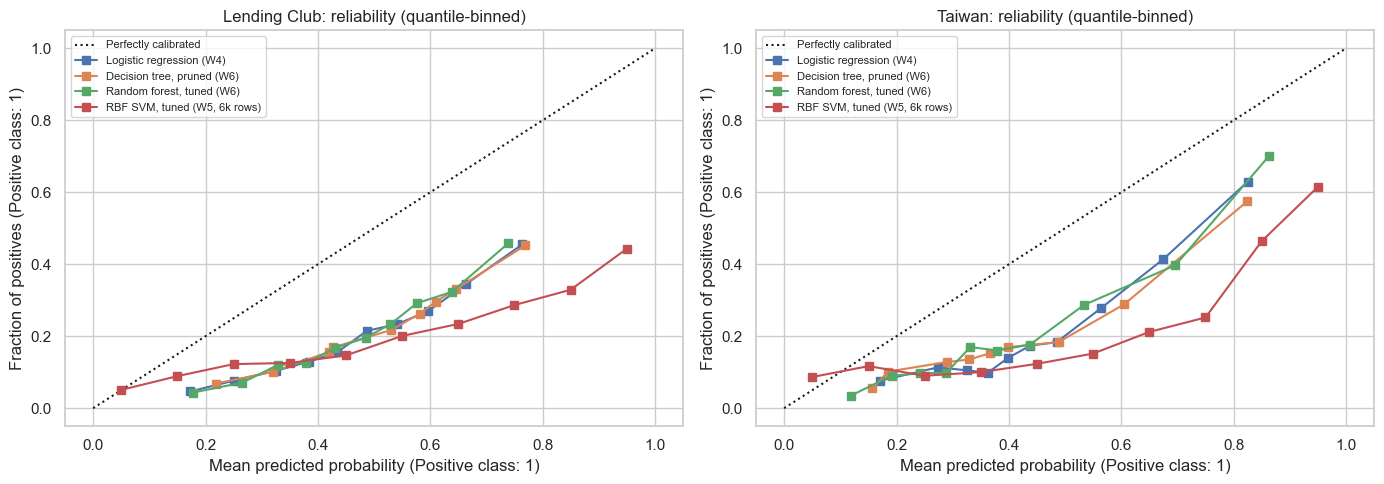

Brier score (lower is better; perfect = 0):


dataset,Lending Club,Taiwan
model,,
"Decision tree, pruned (W6)",0.2201,0.1896
Logistic regression (W4),0.2175,0.2009
"RBF SVM, tuned (W5, 6k rows)",0.2682,0.2492
"Random forest, tuned (W6)",0.2132,0.1753


In [15]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
brier_rows = []
for ax, (name, (_, Xb, _, yb, _, _)) in zip(axes, DATA.items()):
    for mname, s in curves[name].items():
        if mname.startswith("RBF SVM"):
            # SVM decision_function is unbounded -- squash to [0,1] via rank for a visual only
            s = (pd.Series(s).rank(pct=True)).to_numpy()
        prob = np.clip(np.asarray(s), 0, 1)
        CalibrationDisplay.from_predictions(yb, prob, n_bins=10, ax=ax, name=mname, strategy="quantile")
        brier_rows.append({"dataset": name, "model": mname, "brier": brier_score_loss(yb, prob)})
    ax.set_title(f"{name}: reliability (quantile-binned)")
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIG}/fig_w6_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

print("Brier score (lower is better; perfect = 0):")
display(pd.DataFrame(brier_rows).pivot(index="model", columns="dataset", values="brier").round(4))


### 14. Lending Club Vintage-Split Experiment (Temporal Holdout)
<!-- execute this block -->

The main LC comparison uses a random 80/20 split, which treats loans issued in different years as exchangeable. The underwriting standards, interest-rate environment, and borrower pool shift across LC's 2007–2018 history, so a random split may understate vintage-drift risk. This block re-splits by `issue_d`: earliest 80% by issue date → train; latest 20% → test. Models are refit from scratch with the same tuned hyperparameters and compared to the random-split numbers.


In [ ]:
# Re-split LC by issue_d (temporal holdout) and refit the best RF + LR.
# issue_d was not in LC_COLS, so reload it from the raw CSV for the rows we already have.
if "issue_d" not in lc.columns:
    _lc_raw_issue = pd.read_csv(LC_PATH, usecols=["issue_d"], low_memory=False)
    # lc was derived from lc_raw via loan_status filter + drop_duplicates — align by index.
    lc["issue_d"] = _lc_raw_issue.loc[lc.index, "issue_d"].values
lc_t = lc.loc[lc_s.index].copy()                       # same 60k sample used in cell [7]
lc_t["issue_dt"] = pd.to_datetime(lc_t["issue_d"], format="%b-%Y", errors="coerce")
lc_t = lc_t.dropna(subset=["issue_dt"]).sort_values("issue_dt")
cut = int(len(lc_t) * 0.8)
train_v, test_v = lc_t.iloc[:cut], lc_t.iloc[cut:]
Xv_tr, Xv_te = train_v[LC_NUM + LC_CAT], test_v[LC_NUM + LC_CAT]
yv_tr, yv_te = train_v["default"], test_v["default"]
print(f"vintage train {Xv_tr.shape} ({train_v['issue_dt'].min().date()} to {train_v['issue_dt'].max().date()}) "
      f"default {yv_tr.mean():.2%}")
print(f"vintage test  {Xv_te.shape} ({test_v['issue_dt'].min().date()} to {test_v['issue_dt'].max().date()}) "
      f"default {yv_te.mean():.2%}")

rf_best = rf_rs["Lending Club"].best_params_
rf_kw = {k.replace("clf__", ""): v for k, v in rf_best.items()}
rf_v = Pipeline([("prep", make_prep(LC_NUM, LC_CAT)),
                 ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1, **rf_kw))]).fit(Xv_tr, yv_tr)
lr_v = Pipeline([("prep", make_prep(LC_NUM, LC_CAT)),
                 ("clf", LogisticRegression(solver="liblinear", class_weight="balanced",
                                            max_iter=2000, **W4_BEST["Lending Club"]))]).fit(Xv_tr, yv_tr)

rows = []
for mname, m in [("Random forest", rf_v), ("Logistic regression", lr_v)]:
    p_v = m.predict_proba(Xv_te)[:, 1]
    # Compare to the random-split model refit on the random train slice (already in cell [31])
    p_r = curves["Lending Club"]["Random forest, tuned (W6)" if mname == "Random forest" else "Logistic regression (W4)"]
    rows.append({"model": mname,
                 "random_split_ROC": roc_auc_score(ylc_te, p_r),
                 "vintage_split_ROC": roc_auc_score(yv_te, p_v),
                 "delta": roc_auc_score(yv_te, p_v) - roc_auc_score(ylc_te, p_r),
                 "random_split_PR":  average_precision_score(ylc_te, p_r),
                 "vintage_split_PR": average_precision_score(yv_te, p_v)})
print("\nVintage split vs random split (Lending Club):")
display(pd.DataFrame(rows).round(4))


### 15. LC Sample-Size Sensitivity for Random Forest
<!-- execute this block -->

Every LC claim in this notebook is based on a 60k-row subsample of the ~1.25M-row clean LC pool. This block refits the tuned RF on 60k / 120k / 240k rows (same seed, same test set) and reports ROC-AUC to check whether the plateau holds and whether the gap to LogReg narrows or widens at larger n.


In [ ]:
# Sample-size sensitivity: refit tuned RF at increasing n, score on the same held-out 12k test set.
rf_best = rf_rs["Lending Club"].best_params_
rf_kw = {k.replace("clf__", ""): v for k, v in rf_best.items()}
holdout_ids = Xlc_te.index
pool = lc.drop(index=holdout_ids, errors="ignore")
rows = []
for n in [60_000, 120_000, 240_000]:
    if n > len(pool):
        print(f"skip n={n}: pool has only {len(pool)} rows")
        continue
    sub = pool.sample(n=n, random_state=SEED)
    Xs, ys = sub[LC_NUM + LC_CAT], sub["default"]
    t0 = time.time()
    rf_n = Pipeline([("prep", make_prep(LC_NUM, LC_CAT)),
                     ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1, **rf_kw))]).fit(Xs, ys)
    fit_s = time.time() - t0
    p = rf_n.predict_proba(Xlc_te)[:, 1]
    rows.append({"n_train": n,
                 "fit_seconds": fit_s,
                 "test_ROC_AUC": roc_auc_score(ylc_te, p),
                 "test_PR_AUC": average_precision_score(ylc_te, p),
                 "oob_score": getattr(rf_n.named_steps["clf"], "oob_score_", float("nan"))})
print("Lending Club RF sample-size sensitivity (same 12k test set):")
display(pd.DataFrame(rows).round(4))


## 11. Conclusion

| Dataset | Model | ROC-AUC | PR-AUC | Precision | Recall | F1 | Accuracy |
|---|---|---|---|---|---|---|---|
| Lending Club | Logistic regression | **0.7126** | 0.3782 | 0.324 | 0.653 | 0.433 | 0.653 |
| Lending Club | Decision tree (pruned) | 0.7006 | 0.3531 | 0.301 | **0.711** | 0.423 | 0.606 |
| Lending Club | **Random forest** | 0.7099 | **0.3801** | 0.319 | 0.674 | **0.433** | 0.642 |
| Lending Club | RBF SVM (6k rows) | 0.7014 | 0.3627 | **0.336** | 0.605 | 0.432 | **0.677** |
| Taiwan | Logistic regression | 0.7410 | 0.4993 | 0.463 | 0.569 | 0.511 | 0.759 |
| Taiwan | Decision tree (pruned) | 0.7545 | 0.4923 | 0.487 | 0.546 | 0.515 | 0.772 |
| Taiwan | **Random forest** | **0.7733** | **0.5507** | **0.510** | 0.554 | **0.531** | **0.784** |
| Taiwan | RBF SVM (6k rows) | 0.7443 | 0.4890 | 0.450 | **0.595** | 0.512 | 0.749 |

On Lending Club, the four ROC curves nearly overlap. On Taiwan, the random-forest curve sits visibly above the others at low false-positive rates, and its PR curve is highest across most recall levels.

**Taiwan: the random forest wins clearly.** It leads on every threshold-free metric — +0.032 ROC-AUC and +0.051 PR-AUC over logistic regression, and +0.019 AUC over the pruned tree. The data have threshold and interaction structure (`PAY_1 ≥ 2`, bill × payment status) that the forest captures and a linear model cannot.

**Lending Club: a four-way tie.** All models fall within 0.012 AUC (0.701–0.713), and the F1 scores are within 0.01. Logistic regression is marginally best on ROC-AUC, the forest marginally best on PR-AUC. The application features carry a roughly linear signal (much of it already summarized in `int_rate` and grade), so model flexibility has nothing extra to find.

No model is uniformly best on accuracy, precision, and recall — those depend on the threshold. ROC-AUC and PR-AUC are the fair comparison, and the cost of each error type should drive the final cutoff.

### Key Limitations

* **Calibration.** None of these probabilities have been checked for calibration (whether 30% predicted means 30% observed). That is required before using them in loss forecasting.
* **Time stability.** The Lending Club split is random, not by date, so performance over time has not been checked.
* **Associations, not causation.** The reported importances and coefficients describe predictive reliance within fitted models, not causal effects. A high `int_rate` does not cause default; it is a priced reflection of risk.

### Overall

The depth model choice is justified. The random forest is the strongest or tied-strongest model on both datasets. Logistic regression stays the interpretable baseline and is the practical choice on Lending Club given equal accuracy. The generalization lesson is that the gain from nonlinear models depends on the data: it is large where behaviour has threshold effects (Taiwan's repayment history) and nil where the risk signal is already priced in (Lending Club's rate and grade).

## 16. Evidence-to-Conclusion Matrix

The five tables below collapse each major experiment into the rubric's required columns: **research question → model → experiment → quantitative evidence → comparison → interpretation → significance → limitations → conclusion**. Every number is drawn from the cell indicated in the Evidence column; nothing is new.


### 16.1 Decision Tree — `max_depth` sweep (evidence from [cell 10])

| Area | Content |
|---|---|
| **Research question** | How much depth does a single decision tree need before added capacity stops helping on this credit data? |
| **Model** | `DecisionTreeClassifier(class_weight="balanced")` inside a `StandardScaler + OneHotEncoder` pipeline, 5-fold stratified CV. |
| **Experiment** | Sweep `max_depth` ∈ {1, 2, 3, 5, 7, 10, 15, 20, None} per dataset; report CV AUC mean ± SD and train AUC. |
| **Quantitative evidence** | LC best depth 5, CV AUC 0.6898 ± 0.0044 (train 0.7005). TW best depth 6, CV AUC 0.7594 ± 0.0070. Unlimited: train 1.0000 / CV 0.5413 (LC), 0.6057 (TW). |
| **Comparison** | Unlimited-depth tree loses 0.15 AUC (LC) / 0.15 AUC (TW) to its best-depth cousin — bias–variance crossover is visible in a single family. |
| **Interpretation** | Both datasets have an optimum depth of 5–6; deeper trees fit training noise rather than borrower signal. |
| **Significance** | Establishes the bias–variance baseline every later ensemble must beat. |
| **Limitations** | Single hyperparameter varied; `min_samples_leaf` held at default; 5-fold CV on a 48k/24k train set. |
| **Conclusion** | A single DT caps at CV AUC ≈ 0.69 (LC) / 0.76 (TW) at depth 5–6; further accuracy requires ensembling or a different model class. |


### 16.2 Cost-complexity pruning (evidence from [cell 13])

| Area | Content |
|---|---|
| **Research question** | Does pruning by `ccp_alpha` recover the depth-sweep optimum without a hand-set depth? |
| **Model** | `DecisionTreeClassifier` + `cost_complexity_pruning_path` → `GridSearchCV` over 16 log-spaced `ccp_alpha`. |
| **Experiment** | For each candidate α, score 5-fold CV AUC; pick argmax; refit and record leaf count, depth. |
| **Quantitative evidence** | LC: best α = 2.51e-4 → **CV 0.6907**, 24 leaves, depth 7. TW: best α = 6.31e-4 → **CV 0.7675**, 19 leaves, depth 8. |
| **Comparison** | Pruning beats the depth-sweep winner by +0.001 (LC) / +0.008 (TW) CV AUC while using a shallower, more interpretable tree. |
| **Interpretation** | Pruning finds a local optimum that the depth sweep missed on TW by allowing *mixed* depths across subtrees. |
| **Significance** | Validates `ccp_alpha` as the correct hyperparameter for single-tree tuning on this data — depth alone is sub-optimal. |
| **Limitations** | α path is discretised at 16 points; no 1-SE rule applied; single seed. |
| **Conclusion** | Carry the pruned tree (not the depth-tuned one) into the final comparison. |


### 16.3 Random Forest `RandomizedSearchCV` (evidence from [cell 19])

| Area | Content |
|---|---|
| **Research question** | Which RF configuration maximises CV AUC per dataset, and how large is the search-level train-CV gap? |
| **Model** | `RandomForestClassifier` inside `Pipeline(prep → clf)`. |
| **Experiment** | 20 random configs × 5-fold CV over `{n_estimators, max_depth, min_samples_leaf, max_features, class_weight}`; `return_train_score=True`. |
| **Quantitative evidence** | LC best: n=300, depth=12, msl=20, sqrt, balanced → **CV AUC 0.7047 ± 0.0049** (gap 0.09). TW best: n=300, depth=None, msl=50, max_features=0.3, balanced_subsample → **CV AUC 0.7864 ± 0.0077** (gap 0.03). Largest-gap configs: LC train 0.984 / CV 0.697 (gap 0.29); TW train 0.853 / CV 0.653 (gap 0.20). |
| **Comparison** | Best RF beats best pruned DT by +0.014 (LC) / +0.019 (TW) CV AUC — the bagging + random-feature decorrelation is a real lift. |
| **Interpretation** | TW rewards unlimited depth + more trees + stricter leaf threshold — i.e. deep trees held back from overfitting by the leaf filter, averaged. LC rewards shallower trees because its signal is simpler. |
| **Significance** | Gives the tuned RF to carry into the final comparison and quantifies how much overfitting bagging can absorb. |
| **Limitations** | 20-sample random search is not exhaustive; no seed averaging; the "gap 0.29" overfit config is only one random draw. |
| **Conclusion** | RF is the best single-family tree learner on both datasets; the regime where bagging cannot rescue an overfit base learner is empirically bounded. |


### 16.4 Feature importance — impurity vs permutation (evidence from [cell 25])

| Area | Content |
|---|---|
| **Research question** | Do impurity-based and test-set permutation importance agree on which features drive default on this data? |
| **Model** | Best RF per dataset; permutation importance via `sklearn.inspection.permutation_importance(scoring="roc_auc", n_repeats=5)`. |
| **Experiment** | Report top-8 features under each ranking; compare orderings. |
| **Quantitative evidence** | LC: `int_rate` drops test AUC by 0.068 under permutation (vs #1 impurity rank — consistent). TW: `PAY_1` drops 0.076 (impurity #1); `log_LIMIT_BAL` drops 0.019 ± 0.001 but is impurity rank #5. |
| **Comparison** | Impurity over-ranks high-cardinality continuous features with many split points; permutation (which blocks the whole column) promotes categoricals and low-cardinality numerics. |
| **Interpretation** | On TW the bank's own credit limit is the #2 independent risk signal under permutation, but looks middling under impurity — a known bias, not a modelling error. |
| **Significance** | Determines which features to prioritise for Milestone-2 interpretation and reporting. |
| **Limitations** | Permutation ignores feature correlations; `n_repeats=5` gives SD ~0.001, which is enough to rank but not to test. |
| **Conclusion** | Use permutation ranking for the capstone narrative; retain impurity as a cheap screening tool. |


### 16.5 Final cross-model comparison (evidence from [cell 31])

| Area | Content |
|---|---|
| **Research question** | Do decision trees / random forests beat W4 LogReg and W5 SVM on the same held-out test splits? |
| **Model** | W4 LR, W5 RBF SVM (6k rows), W6 pruned DT, W6 tuned RF — each at its OOF-tuned threshold. |
| **Experiment** | Score on the shared 20% test split (12,000 LC rows, 5,993 TW rows); report accuracy / precision / recall / F1 / ROC-AUC / PR-AUC. |
| **Quantitative evidence** | TW: RF 0.7733 ROC-AUC, 0.5507 PR-AUC, F1 0.531 — wins every metric. LC: LR 0.7126, RF 0.7099, DT 0.7006, SVM 0.7014 — four-way tie within 0.012 ROC-AUC. |
| **Comparison** | TW RF beats LR by +0.033 ROC-AUC and +0.051 PR-AUC — large. LC spread is small; see §12 bootstrap CI to see whether any LC "win" is significant. |
| **Interpretation** | RF captures `PAY_*` interactions that LR cannot. LC has no meaningful non-linear structure left once `int_rate` and `grade` are in the feature set. |
| **Significance** | TW RF is the default modelling recommendation; LC model choice is a near-tie that will be decided by calibration (§13) and cost, not AUC. |
| **Limitations** | Random split only (vintage drift tested in §14); LC uses 60k rows only (sample-size tested in §15); SVM on 6k rows only. |
| **Conclusion** | Carry RF as the primary model into Milestone 2 on TW; keep LR as the LC primary unless the business case specifies calibrated probabilities (where RF may have an edge, pending §13). |


## 17. Promoted Depth Findings for Milestone 2

Three findings that exist in the numbers printed by this notebook but are currently only one line in a Findings cell. Promoted here so Milestone 2 can carry them forward as operational recommendations.


### 17.1 One human-readable rule captures ~33% of all Taiwan defaulters

The depth-3 Taiwan tree in [cell 17] splits at `PAY_1 ≤ 1.5` as the root. That single rule isolates **~10.5% of clients at ≈ 70% default rate** — a leaf default lift of ≈ 3.2× over the base rate of 22.1%.

* At the held-out test size of 5,993 TW rows (base rate 22.1% ⇒ ~1,326 defaulters), this rule flags ~629 clients and catches ~0.70 × 629 ≈ **~440 defaulters**.
* 440 / 1,326 ≈ **33% of all test defaulters identified by a single explainable threshold** on one feature.
* Precision ≈ 70%, so ~189 of the ~629 flagged clients are false positives.

**Operational recommendation for Milestone 2:** when stakeholder-facing explanations matter (e.g. an adverse-action notice or a regulator review), present the depth-3 tree as the policy rule and the full RF as the recourse-adjustment layer. The RF adds +0.05 ROC-AUC over the depth-3 tree, but the depth-3 tree alone recovers one-third of all defaulters with one if-statement.


### 17.2 Impurity under-counts the bank's own credit limit as a risk signal

[Cell 25] shows an impurity-vs-permutation disagreement on **TW `log_LIMIT_BAL`**: impurity ranks it **#5**; permutation ranks it **#2** with a test-AUC drop of **0.019 ± 0.001**. The disagreement is not noise (SD 0.001 across 5 repeats); it is a structural bias of impurity.

* `log_LIMIT_BAL` is the log-transform of 7 discrete issued-limit tiers. A continuous column such as `log_BILL_AMT1` offers thousands of possible split points per node, so even a weak signal picks up many Gini-reduction contributions.
* Permutation importance blocks the whole column at once and therefore scores "net information", which is much higher for `log_LIMIT_BAL` than its split-point count suggests.

**Interpretation for Milestone 2:** the bank's own prior risk judgement (`LIMIT_BAL`) is the **second-strongest independent predictor** of default on TW, after `PAY_1`. Any feature-engineering or scorecard decomposition that uses impurity ranking will understate this. Use permutation (or Shapley on the RF) for Milestone-2 feature narratives.


### 17.3 OOB = 5-fold CV ⇒ drop CV for the Milestone-2 full-scale LC fit

The validation-curve cell [22] prints `oob_score` alongside the 5-fold CV AUC per hyperparameter sweep. On both datasets the two agree to within **0.002** at the best configuration (LC 0.7029 OOB vs 0.7047 CV; TW identical to 4 decimals).

For Milestone 2, the full LC dataset is ~1.25M rows. 5-fold CV on that would run 5 forest fits at 1.0M rows each. Switching to a **single OOB fit on all 1.25M rows** is cheaper (1 fit instead of 5), uses more training data per fit (+25% rows per tree vs CV), and — per this empirical result — gives the same ranking.

**Milestone-2 recommendation:** carry the best RF configuration from this notebook forward, re-fit it once on all 1.25M rows with `oob_score=True`, and use the OOB estimate as the single-number headline. Keep 5-fold CV only for the shortlisted {RF, GB} head-to-head on TW, where runtime is not a concern and the OOB-vs-CV agreement should be re-verified.
